# AgriPulse 01: Warehouse, EDA and OLAP

**Question:** can a country's crop-yield *shock* be detected from rainfall deviation, temperature anomaly
and pesticide intensity, and do the patterns differ by crop and region?

This notebook:

1. builds the Medallion layers (Bronze → Silver → Gold) from the four source files,
2. documents the data-quality findings that shape the analysis,
3. runs exploratory data analysis (descriptive statistics, histograms, boxplots, correlation),
4. runs OLAP-style roll-ups of the shock rate by crop, region, decade and climate band.

The SQL Server warehouse in `sql/` is the reference implementation; `agripulse.pipeline` applies the same
rules in pandas so the notebooks run anywhere (see `README.md`).

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from agripulse import config as cfg, pipeline, plotting as viz

viz.apply_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)
TABLES = ROOT / "reports" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)

## 1. Build the Medallion layers

In [2]:
layers = pipeline.run()   # Bronze -> Silver -> Gold, writes datasets/gold/*.csv
bronze, silver, gold = layers["bronze"], layers["silver"], layers["gold"]

counts = pd.DataFrame(
    [(layer, name, len(df)) for layer, tables in layers.items() for name, df in tables.items()],
    columns=["layer", "table", "rows"],
)
counts

,layer,table,rows
0,bronze,fao_yield,56717
1,bronze,wb_rainfall,6727
2,bronze,wb_temperature,71311
3,bronze,fao_pesticides,4349
4,bronze,ref_country,210
5,bronze,ref_country_alias,41
6,silver,country,210
7,silver,fao_yield,56261
8,silver,wb_rainfall,6336
9,silver,wb_temperature,27479


### What Silver changed

* **FAO yield.** The FAO file has both `China` (area 351, an aggregate of mainland, Hong Kong, Macao and
  Taiwan) and its parts, so the aggregate is dropped to avoid double counting. Yields of 0 hg/ha mark
  missing records in FAO data and are removed.
* **Temperature.** The file has one row per *city*, so a country-year can appear up to 52 times
  (United States). Silver averages them. The pre-merged `yield_df.csv` on Kaggle skips this step, so its
  rows are duplicated.
* **Country names.** The four sources spell countries differently (`Viet Nam`/`Vietnam`,
  `Congo, Dem. Rep.`/`Congo (Democratic Republic Of The)`, ...). Every spelling is mapped to one conformed
  name through `datasets/reference/country_aliases.csv`.
* **Rainfall.** Blank cells, and the years 1988 and 2003 that are missing from the file, are filled with the
  country mean and flagged `is_imputed = 1`.

In [3]:
b_yield = bronze["fao_yield"]
b_value = pd.to_numeric(b_yield.value, errors="coerce")
silver_summary = pd.Series({
    "yield rows in Bronze": len(b_yield),
    'dropped: FAO "China" aggregate (area 351)': int((b_yield.area_code.str.strip() == "351").sum()),
    "dropped: yield <= 0 (missing in FAO)": int((b_value <= 0).sum()),
    "yield rows in Silver": len(silver["fao_yield"]),
    "temperature city records (Bronze)": len(bronze["wb_temperature"]),
    "temperature country-years (Silver)": len(silver["wb_temperature"]),
    "max city records in one country-year": int(silver["wb_temperature"].n_records.max()),
    "rainfall country-years imputed (Silver)": int(silver["wb_rainfall"].is_imputed.sum()),
    "country spellings remapped": len(bronze["ref_country_alias"]),
}, name="value")
silver_summary.to_frame()

,value
yield rows in Bronze,56717
"dropped: FAO ""China"" aggregate (area 351)",448
dropped: yield <= 0 (missing in FAO),8
yield rows in Silver,56261
temperature city records (Bronze),71311
temperature country-years (Silver),27479
max city records in one country-year,52
rainfall country-years imputed (Silver),389
country spellings remapped,41


## 2. Data-quality finding: the rainfall source does not vary over time

The proposal measures rainfall stress as each country's deviation from its long-term average. Profiling
shows that the Kaggle rainfall file repeats one long-term value for nearly every country and year, so the
deviation is zero almost everywhere. This affects every model below and is reported as a limitation.

In [4]:
rain_obs = silver["wb_rainfall"].query("is_imputed == 0")
distinct = rain_obs.groupby("country_name").rainfall_mm.nunique()
ml = gold["ml_dataset"]
nonzero = (ml.rain_dev_pct.abs() > 0.01).mean()

print(f"{(distinct == 1).sum()} of {len(distinct)} countries report the same rainfall in every year")
print("countries with more than one value:", ", ".join(distinct[distinct > 1].index))
print(f"Gold rows with any rainfall deviation: {nonzero:.1%}")
rain_obs[rain_obs.country_name.isin(["Afghanistan", "India", "Brazil"])].pivot(
    index="country_name", columns="year", values="rainfall_mm").iloc[:, ::4]

188 of 192 countries report the same rainfall in every year
countries with more than one value: Argentina, Barbados, India, Paraguay
Gold rows with any rainfall deviation: 2.3%


year,1985,1990,1994,1998,2002,2007,2011,2015
country_name,,,,,,,,
Afghanistan,327.000,327.000,327.000,327.000,327.000,327.000,327.000,327.000
Brazil,"1,761.000","1,761.000","1,761.000","1,761.000","1,761.000","1,761.000","1,761.000","1,761.000"
India,"1,940.000","1,083.000","1,083.000","1,083.000","1,083.000","1,083.000","1,083.000","1,083.000"


## 3. The Gold dataset

One row per country x crop x year (1990-2013, where all four sources overlap). The label is
`is_shock = 1` when the yield is at least 15 % below the mean of the previous five years for the same
country and crop.

In [5]:
print(f"{len(ml):,} crop-years | {ml.country_name.nunique()} countries | "
      f"{ml.crop_name.nunique()} crops | {ml.year.min()}-{ml.year.max()}")
print(f"shocks: {ml.is_shock.sum():,} ({ml.is_shock.mean():.1%} of crop-years)")
ml.head()

16,339 crop-years | 119 countries | 10 crops | 1990-2013
shocks: 1,667 (10.2% of crop-years)


,country_name,iso3,region,crop_name,crop_group,year,decade,climate_band,temp_band,rain_band,yield_hg_ha,prev_yield_hg_ha,yoy_change_pct,baseline_yield_hg_ha,yield_dev_pct,is_shock,prev_yield_dev_pct,prev_is_shock,rainfall_mm,rain_dev_pct,rain_is_imputed,avg_temp_c,temp_anomaly_c,pesticides_tonnes,pesticide_intensity,pesticide_yoy_pct
0,Albania,ALB,Europe & Central Asia,Maize,Cereals,1990,1990s,Temperate / Humid,Temperate,Humid,"36,613.000","47,969.000",-23.674,"39,836.200",-8.091,0,27.292,0,"1,485.000",0.000,0,16.370,0.681,121.000,2.086,NaN
1,Albania,ALB,Europe & Central Asia,Maize,Cereals,1991,1990s,Temperate / Humid,Temperate,Humid,"29,068.000","36,613.000",-20.607,"40,133.200",-27.571,1,-8.091,0,"1,485.000",0.000,0,15.360,-0.329,121.000,2.086,0.000
2,Albania,ALB,Europe & Central Asia,Maize,Cereals,1992,1990s,Temperate / Humid,Temperate,Humid,"24,876.000","29,068.000",-14.421,"36,933.800",-32.647,1,-27.571,1,"1,485.000",0.000,0,16.060,0.371,121.000,2.086,0.000
3,Albania,ALB,Europe & Central Asia,Maize,Cereals,1993,1990s,Temperate / Humid,Temperate,Humid,"24,185.000","24,876.000",-2.778,"34,279.400",-29.447,1,-32.647,1,"1,485.000",0.000,0,16.050,0.361,121.000,2.086,0.000
4,Albania,ALB,Europe & Central Asia,Maize,Cereals,1994,1990s,Temperate / Humid,Temperate,Humid,"25,848.000","24,185.000",6.876,"32,542.200",-20.571,1,-29.447,1,"1,485.000",0.000,0,16.960,1.271,201.000,2.305,66.116


## 4. Exploratory data analysis

### 4.1 Descriptive statistics

In [6]:
num_cols = ["yield_hg_ha", "yield_dev_pct", "yoy_change_pct", "rainfall_mm", "rain_dev_pct",
            "avg_temp_c", "temp_anomaly_c", "pesticides_tonnes", "pesticide_intensity",
            "pesticide_yoy_pct", "prev_yield_dev_pct"]
desc = ml[num_cols].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T
desc["skew"] = ml[num_cols].skew()
desc.to_csv(TABLES / "eda_descriptive_statistics.csv")
desc

,count,mean,std,min,5%,25%,50%,75%,95%,max,skew
yield_hg_ha,"16,339.000","69,571.215","77,254.656",100.000,"7,000.900","18,018.000","39,310.000","94,236.500","229,245.100","501,412.000",2.104
yield_dev_pct,"16,339.000",5.189,24.982,-91.771,-26.361,-3.835,2.755,11.562,39.633,677.807,4.793
yoy_change_pct,"16,334.000",4.088,33.035,-86.408,-24.573,-4.404,0.549,7.373,38.839,"2,095.536",20.035
rainfall_mm,"16,339.000","1,163.204",715.358,51.000,151.000,624.000,"1,110.000","1,651.000","2,387.000","3,240.000",0.679
rain_dev_pct,"16,339.000",-0.026,0.263,-2.489,0.000,0.000,0.000,0.000,0.000,0.159,-9.205
avg_temp_c,"16,339.000",19.805,6.785,1.300,8.179,14.978,20.680,26.050,27.835,30.420,-0.509
temp_anomaly_c,"16,339.000",0.554,0.488,-1.567,-0.125,0.250,0.495,0.811,1.418,2.959,0.677
pesticides_tonnes,"16,339.000","33,006.852","154,157.256",0.040,14.790,218.600,"2,377.000","13,984.910","82,439.060","1,806,000.000",8.498
pesticide_intensity,"16,339.000",3.237,1.219,0.017,1.198,2.342,3.376,4.146,4.916,6.257,-0.309
pesticide_yoy_pct,"15,729.000",48.120,894.007,-99.907,-36.908,-4.795,0.000,8.680,66.509,"36,571.429",33.143


### 4.2 Distributions

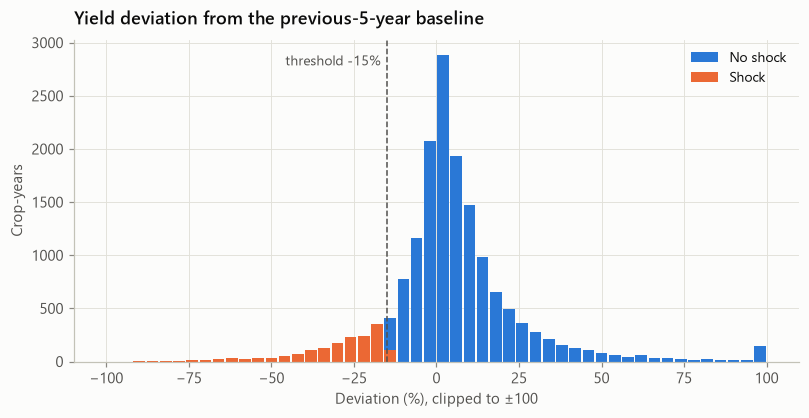

In [7]:
bins = np.arange(-100, 104, 4)
vals = ml.yield_dev_pct.clip(-100, 100)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.hist(vals[ml.is_shock == 0], bins=bins, color=viz.NO_SHOCK, rwidth=0.88, label="No shock")
ax.hist(vals[ml.is_shock == 1], bins=bins, color=viz.SHOCK, rwidth=0.88, label="Shock")
ax.axvline(cfg.SHOCK_THRESHOLD_PCT, color=viz.INK_2, lw=1, ls="--")
ax.text(cfg.SHOCK_THRESHOLD_PCT - 2, ax.get_ylim()[1] * 0.92, f"threshold {cfg.SHOCK_THRESHOLD_PCT:.0f}%",
        ha="right", color=viz.INK_2, fontsize=9)
ax.set(title="Yield deviation from the previous-5-year baseline",
       xlabel="Deviation (%), clipped to ±100", ylabel="Crop-years")
ax.legend(loc="upper right")
viz.save(fig, "fig01_yield_deviation_hist")
plt.show()

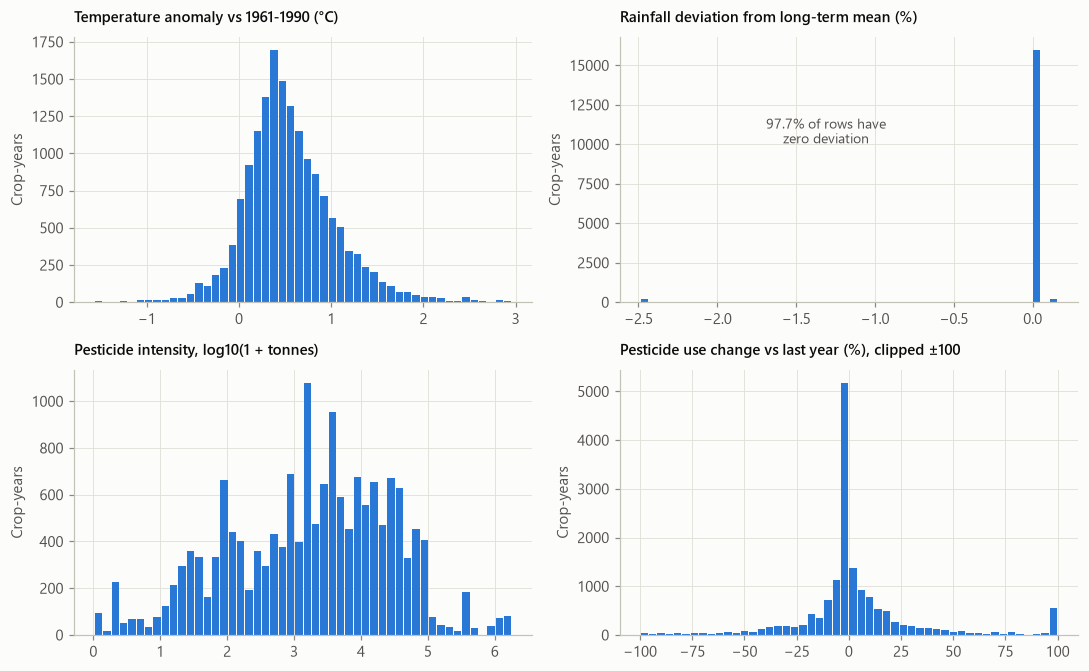

In [8]:
panels = [
    ("temp_anomaly_c", "Temperature anomaly vs 1961-1990 (°C)", None),
    ("rain_dev_pct", "Rainfall deviation from long-term mean (%)", None),
    ("pesticide_intensity", "Pesticide intensity, log10(1 + tonnes)", None),
    ("pesticide_yoy_pct", "Pesticide use change vs last year (%), clipped ±100", (-100, 100)),
]
fig, axes = plt.subplots(2, 2, figsize=(10, 6.2))
for ax, (col, label, clip) in zip(axes.flat, panels):
    v = ml[col].dropna()
    if clip:
        v = v.clip(*clip)
    ax.hist(v, bins=50, color=viz.SERIES[0], rwidth=0.88)
    ax.set_title(label, fontsize=10)
    ax.set_ylabel("Crop-years")
axes[0, 1].text(0.45, 0.6, f"{1 - nonzero:.1%} of rows have\nzero deviation",
                transform=axes[0, 1].transAxes, ha="center", color=viz.INK_2, fontsize=9)
fig.tight_layout()
viz.save(fig, "fig02_feature_distributions")
plt.show()

### 4.3 Boxplots

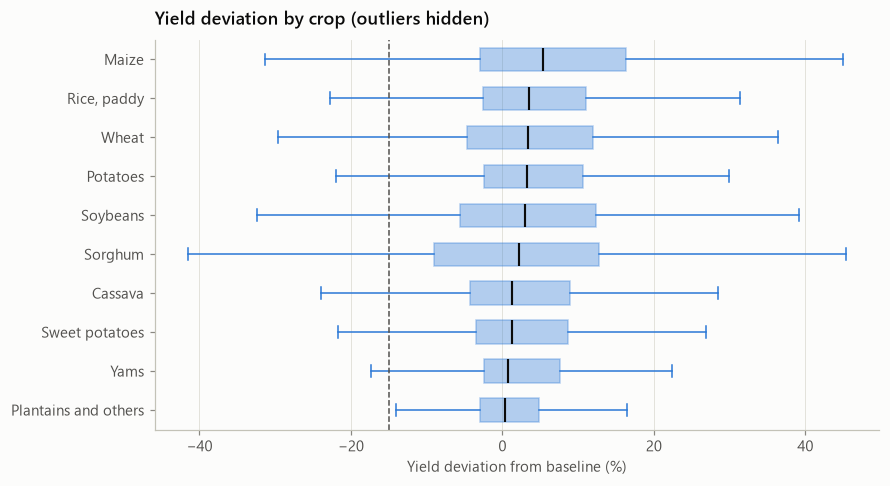

In [9]:
def boxes(ax, data, labels, colors):
    bp = ax.boxplot(data, tick_labels=labels, orientation="horizontal", showfliers=False,
                    patch_artist=True, widths=0.6, medianprops=dict(color=viz.INK, lw=1.4))
    for patch, c in zip(bp["boxes"], colors):
        patch.set(facecolor=c, alpha=0.35, edgecolor=c)
    for part in ("whiskers", "caps"):
        for line, c in zip(bp[part], np.repeat(colors, 2)):
            line.set(color=c)
    return bp

order = ml.groupby("crop_name").yield_dev_pct.median().sort_values().index
fig, ax = plt.subplots(figsize=(8.5, 4.6))
boxes(ax, [ml.loc[ml.crop_name == c, "yield_dev_pct"] for c in order], order, [viz.SERIES[0]] * len(order))
ax.axvline(cfg.SHOCK_THRESHOLD_PCT, color=viz.INK_2, lw=1, ls="--")
ax.set(title="Yield deviation by crop (outliers hidden)", xlabel="Yield deviation from baseline (%)")
ax.grid(axis="y", visible=False)
viz.save(fig, "fig03_yield_deviation_by_crop")
plt.show()

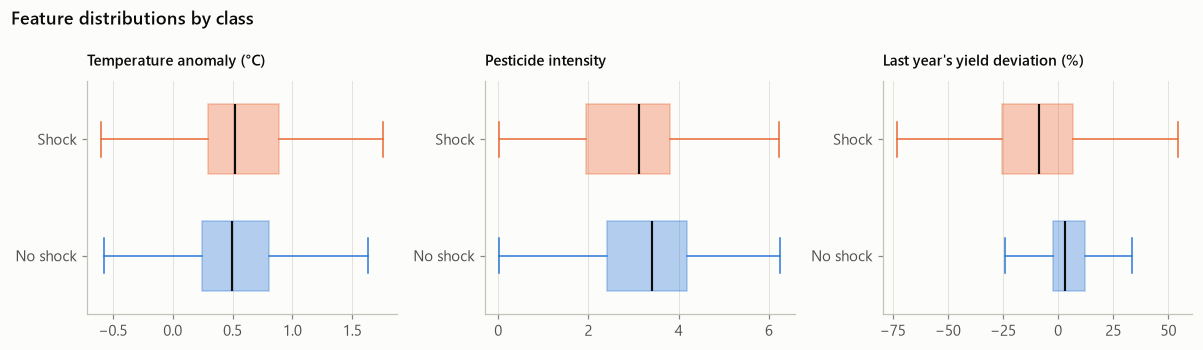

In [10]:
feat = [("temp_anomaly_c", "Temperature anomaly (°C)"),
        ("pesticide_intensity", "Pesticide intensity"),
        ("prev_yield_dev_pct", "Last year's yield deviation (%)")]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, (col, label) in zip(axes, feat):
    d = ml.dropna(subset=[col])
    boxes(ax, [d.loc[d.is_shock == 0, col], d.loc[d.is_shock == 1, col]],
          ["No shock", "Shock"], [viz.NO_SHOCK, viz.SHOCK])
    ax.set_title(label, fontsize=10)
    ax.grid(axis="y", visible=False)
fig.suptitle("Feature distributions by class", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout()
viz.save(fig, "fig04_features_by_class")
plt.show()

### 4.4 Correlation

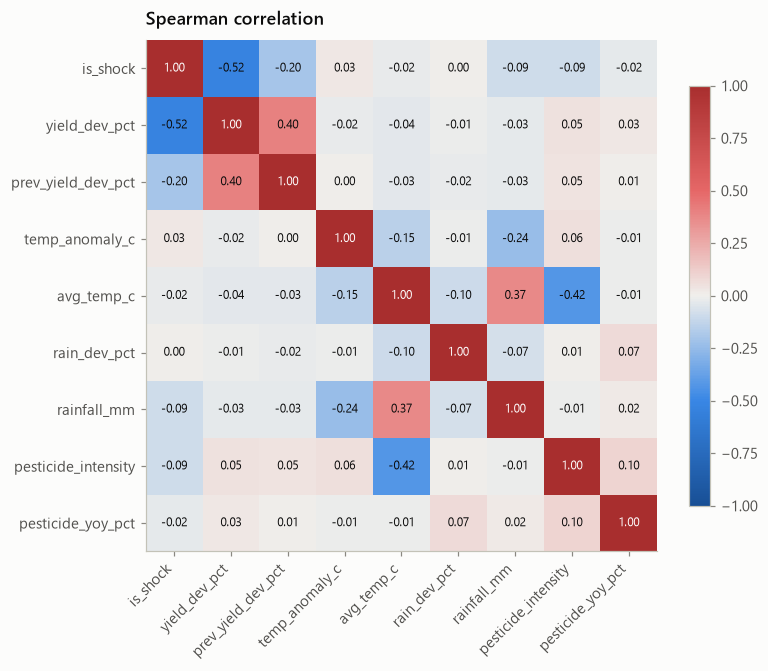

yield_dev_pct         -0.524
prev_yield_dev_pct    -0.198
rainfall_mm           -0.087
pesticide_intensity   -0.087
pesticide_yoy_pct     -0.025
avg_temp_c            -0.020
rain_dev_pct           0.004
temp_anomaly_c         0.030
Name: is_shock, dtype: float64

In [11]:
corr_cols = ["is_shock", "yield_dev_pct", "prev_yield_dev_pct", "temp_anomaly_c", "avg_temp_c",
             "rain_dev_pct", "rainfall_mm", "pesticide_intensity", "pesticide_yoy_pct"]
corr = ml[corr_cols].corr(method="spearman")
corr.to_csv(TABLES / "eda_spearman_correlation.csv")

fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(corr, cmap=viz.DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 else viz.INK)
ax.grid(False)
ax.set_title("Spearman correlation")
fig.colorbar(im, ax=ax, shrink=0.8)
viz.save(fig, "fig05_correlation")
plt.show()
corr["is_shock"].drop("is_shock").sort_values()

## 5. OLAP roll-ups

These are the pandas versions of the queries in `sql/08_olap_analysis.sql` (ROLLUP, CUBE, PIVOT, slice,
dice, drill-down).

### 5.1 Roll-up: region x crop group (with subtotals)

In [12]:
rate = ml.pivot_table(index="region", columns="crop_group", values="is_shock",
                      aggfunc="mean", margins=True, margins_name="All") * 100
n = ml.pivot_table(index="region", columns="crop_group", values="is_shock",
                   aggfunc="count", margins=True, margins_name="All")
rate.to_csv(TABLES / "olap_shock_rate_region_x_cropgroup.csv")
rate.round(1)

crop_group,Cereals,Oilseeds,Roots & Tubers,Starchy Fruits,All
region,,,,,
East Asia & Pacific,3.300,6.700,4.900,NaN,4.300
Europe & Central Asia,12.800,15.700,6.400,NaN,11.500
Latin America & Caribbean,7.600,10.300,5.400,10.400,7.300
Middle East & North Africa,13.400,10.100,7.300,NaN,11.500
North America,6.200,2.100,6.900,NaN,5.700
South Asia,1.900,9.800,1.100,0.000,2.600
Sub-Saharan Africa,18.700,17.400,10.700,1.100,14.500
All,12.100,12.600,7.300,6.100,10.200


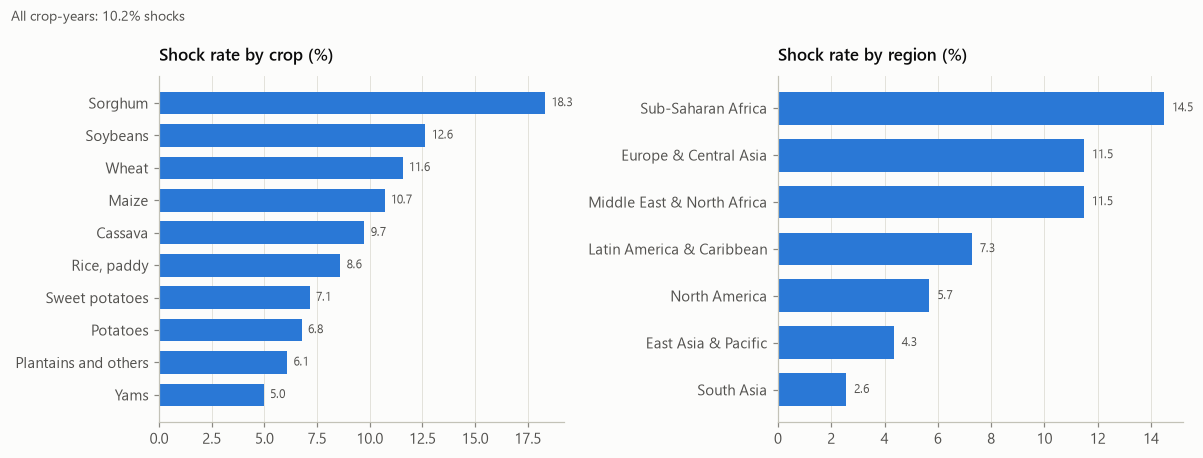

In [13]:
overall = ml.is_shock.mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, dim, title in [(axes[0], "crop_name", "by crop"), (axes[1], "region", "by region")]:
    s = (ml.groupby(dim).is_shock.mean() * 100).sort_values()
    ax.barh(s.index, s.values, color=viz.SERIES[0], height=0.7)
    for y, v in enumerate(s.values):
        ax.text(v + 0.3, y, f"{v:.1f}", va="center", fontsize=8, color=viz.INK_2)
    ax.set_title(f"Shock rate {title} (%)", fontsize=11)
    ax.grid(axis="y", visible=False)
fig.suptitle(f"All crop-years: {overall:.1f}% shocks", x=0.01, ha="left", fontsize=9, color=viz.INK_2)
fig.tight_layout()
viz.save(fig, "fig06_shock_rate_crop_region")
plt.show()

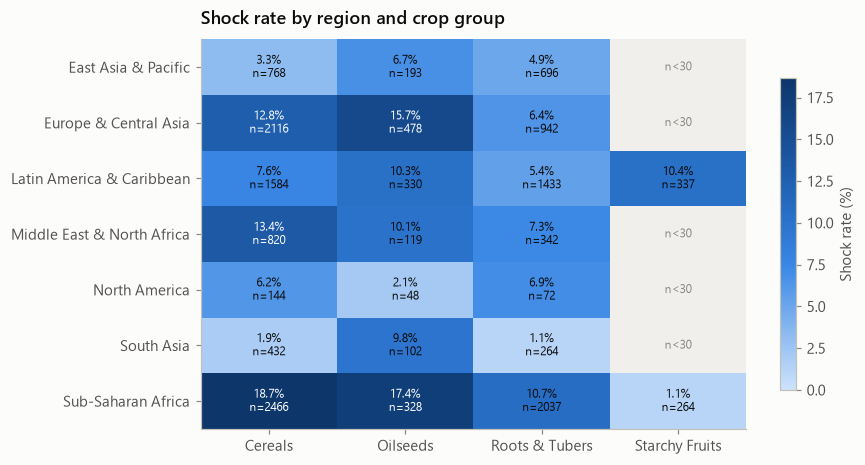

In [14]:
r = rate.drop(index="All", columns="All")
cnt = n.drop(index="All", columns="All")
fig, ax = plt.subplots(figsize=(8, 4.6))
masked = np.ma.masked_where(cnt.fillna(0).to_numpy() < 30, r.to_numpy())
cmap = viz.SEQUENTIAL.copy()
cmap.set_bad("#f0efec")
im = ax.imshow(masked, cmap=cmap, vmin=0, aspect="auto")
ax.set_xticks(range(r.shape[1]), r.columns)
ax.set_yticks(range(r.shape[0]), r.index)
for i in range(r.shape[0]):
    for j in range(r.shape[1]):
        c = cnt.iloc[i, j]
        if pd.isna(c) or c < 30:
            ax.text(j, i, "n<30", ha="center", va="center", fontsize=8, color=viz.MUTED)
        else:
            v = r.iloc[i, j]
            ax.text(j, i, f"{v:.1f}%\nn={int(c)}", ha="center", va="center", fontsize=8,
                    color="white" if v > np.nanmax(masked) * 0.6 else viz.INK)
ax.grid(False)
ax.set_title("Shock rate by region and crop group")
fig.colorbar(im, ax=ax, shrink=0.8, label="Shock rate (%)")
viz.save(fig, "fig07_heatmap_region_cropgroup")
plt.show()

### 5.2 Change over time (CUBE over decade x crop group, and yearly trend)

In [15]:
cube = ml.pivot_table(index="crop_group", columns="decade", values="is_shock",
                      aggfunc="mean", margins=True, margins_name="All") * 100
cube.round(1)

decade,1990s,2000s,2010s,All
crop_group,,,,
Cereals,13.300,11.400,11.000,12.100
Oilseeds,12.400,12.000,14.800,12.600
Roots & Tubers,8.000,7.200,5.800,7.300
Starchy Fruits,4.200,8.100,5.700,6.100
All,11.000,9.800,9.400,10.200


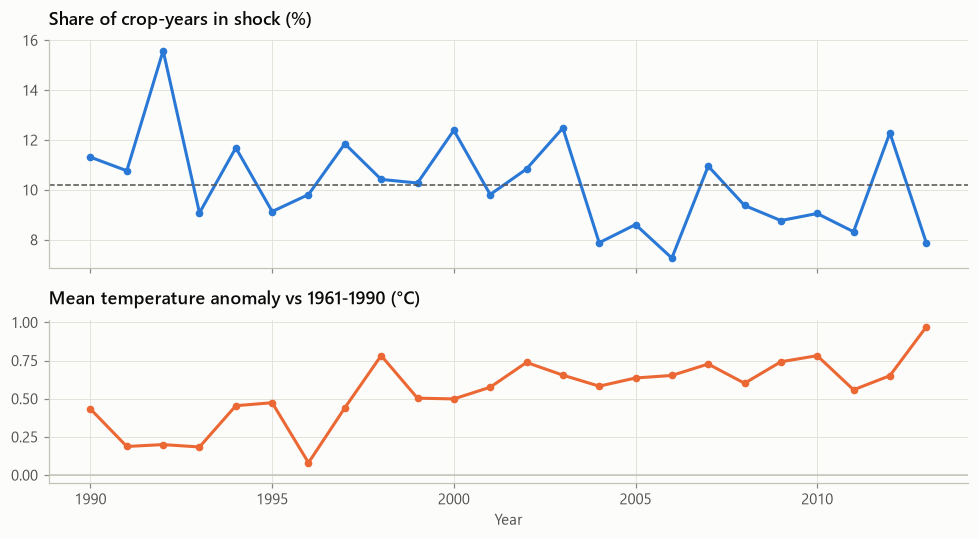

,shock_rate,temp_anomaly
year,,
1992,0.156,0.200
2003,0.125,0.654
2000,0.124,0.499
2012,0.123,0.651
1997,0.118,0.441


In [16]:
by_year = ml.groupby("year").agg(shock_rate=("is_shock", "mean"), temp_anomaly=("temp_anomaly_c", "mean"))
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5), sharex=True, height_ratios=[1.4, 1])
ax1.plot(by_year.index, by_year.shock_rate * 100, color=viz.SERIES[0], marker="o", ms=4)
ax1.axhline(overall, color=viz.INK_2, lw=1, ls="--")
ax1.set(title="Share of crop-years in shock (%)")
ax2.plot(by_year.index, by_year.temp_anomaly, color=viz.SERIES[1], marker="o", ms=4)
ax2.axhline(0, color=viz.AXIS, lw=1)
ax2.set(title="Mean temperature anomaly vs 1961-1990 (°C)", xlabel="Year")
fig.tight_layout()
viz.save(fig, "fig08_trend_by_year")
plt.show()
by_year.sort_values("shock_rate", ascending=False).head(5)

### 5.3 Slice and dice: climate stress vs. shock rate

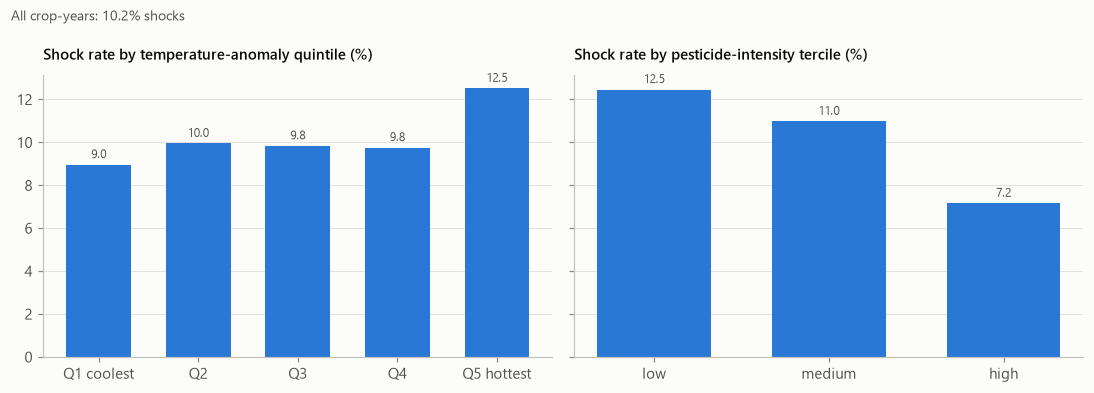

In [17]:
q = ml.assign(
    temp_quintile=pd.qcut(ml.temp_anomaly_c, 5, labels=["Q1 coolest", "Q2", "Q3", "Q4", "Q5 hottest"]),
    pest_tercile=pd.qcut(ml.pesticide_intensity, 3, labels=["low", "medium", "high"]),
)
t_rate = q.groupby("temp_quintile", observed=True).is_shock.mean() * 100
p_rate = q.groupby("pest_tercile", observed=True).is_shock.mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, s, title in [(axes[0], t_rate, "by temperature-anomaly quintile"),
                     (axes[1], p_rate, "by pesticide-intensity tercile")]:
    ax.bar(s.index.astype(str), s.values, color=viz.SERIES[0], width=0.65)
    for x, v in enumerate(s.values):
        ax.text(x, v + 0.3, f"{v:.1f}", ha="center", fontsize=8, color=viz.INK_2)
    ax.set_title(f"Shock rate {title} (%)", fontsize=10)
    ax.grid(axis="x", visible=False)
fig.suptitle(f"All crop-years: {overall:.1f}% shocks", x=0.01, ha="left", fontsize=9, color=viz.INK_2)
fig.tight_layout()
viz.save(fig, "fig09_shock_rate_temp_pesticide")
plt.show()

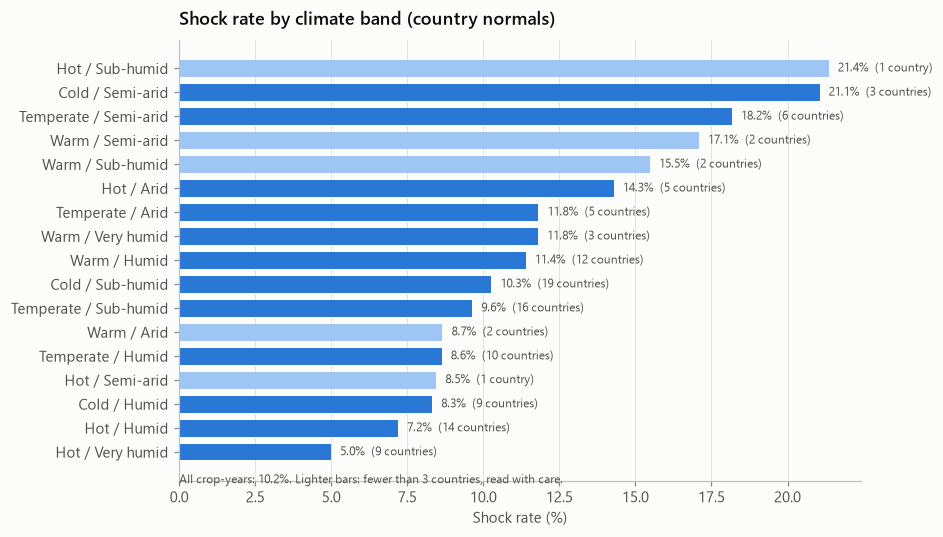

In [18]:
band = (ml.groupby("climate_band")
          .agg(countries=("country_name", "nunique"), crop_years=("is_shock", "size"),
               shock_rate=("is_shock", "mean"))
          .sort_values("shock_rate"))
band["shock_rate"] *= 100
band.to_csv(TABLES / "olap_shock_rate_climate_band.csv")

fig, ax = plt.subplots(figsize=(8, 5.2))
colors = [viz.SERIES[0] if c >= 3 else "#9ec5f4" for c in band.countries]
ax.barh(band.index, band.shock_rate, color=colors, height=0.7)
for y, (v, c) in enumerate(zip(band.shock_rate, band.countries)):
    ax.text(v + 0.3, y, f"{v:.1f}%  ({c} {'country' if c == 1 else 'countries'})",
            va="center", fontsize=8, color=viz.INK_2)
ax.set(title="Shock rate by climate band (country normals)", xlabel="Shock rate (%)")
ax.text(0, -1.3, f"All crop-years: {overall:.1f}%. Lighter bars: fewer than 3 countries, read with care.",
        fontsize=8, color=viz.INK_2)
ax.grid(axis="y", visible=False)
viz.save(fig, "fig10_shock_rate_climate_band")
plt.show()

In [19]:
# Dice: cereals in Sub-Saharan Africa, hot-anomaly years vs. the rest (sql Q5)
ssa_cereal = ml[(ml.region == "Sub-Saharan Africa") & (ml.crop_group == "Cereals")]
(ssa_cereal.assign(temperature=np.where(ssa_cereal.temp_anomaly_c > 1, "anomaly > +1 °C", "anomaly <= +1 °C"))
           .groupby("temperature").is_shock.agg(crop_years="size", shock_rate="mean"))

,crop_years,shock_rate
temperature,,
anomaly <= +1 °C,2311,0.180
anomaly > +1 °C,155,0.284


In [20]:
# Drill-down: most shock-prone country x crop series (>= 15 years observed)
series = (ml.groupby(["country_name", "crop_name"])
            .agg(years=("is_shock", "size"), shocks=("is_shock", "sum"),
                 shock_rate=("is_shock", "mean"), worst_dev_pct=("yield_dev_pct", "min"))
            .query("years >= 15")
            .sort_values(["shock_rate", "shocks"], ascending=False))
series.head(15)

,,years,shocks,shock_rate,worst_dev_pct
country_name,crop_name,,,,
Eritrea,Sorghum,18,13,0.722,-79.123
Kazakhstan,Sorghum,19,13,0.684,-83.509
Botswana,Maize,24,13,0.542,-74.521
Cameroon,"Rice, paddy",24,13,0.542,-65.741
Moldova,Sorghum,19,10,0.526,-68.176
Lesotho,Wheat,24,12,0.500,-71.558
Zambia,Sweet potatoes,24,12,0.500,-66.387
Zimbabwe,Sorghum,24,12,0.500,-41.973
Angola,Potatoes,24,11,0.458,-55.078


In [21]:
# Persistence: P(shock | last year's label)
ml.groupby("prev_is_shock", dropna=False).is_shock.agg(crop_years="size", shock_rate="mean")

,crop_years,shock_rate
prev_is_shock,,
0,14559,0.069
1,1662,0.386
<NA>,118,0.144


## 6. Takeaways

(Numbers from the default configuration: −15 % threshold, 5-year baseline, 1990-2013.)

* **Gold dataset:** 16,339 crop-years from 119 countries and 10 crops, 1,667 of them shocks (10.2 %).
  90 of the 209 yield entities drop out because one source does not cover them. For example, Nigeria,
  the Philippines and DR Congo have no pesticide data, and Ethiopia and Myanmar have no temperature data.
* **Rainfall deviation is not usable from this source.** 188 of 192 countries have one rainfall value
  repeated every year. The other four change only once, which looks like a revision (India: 1,940 mm in
  1985, then 1,083 mm). The deviation is zero for 97.7 % of Gold rows. Rainfall can only enter the analysis
  as a static aridity level (rainfall_mm, climate band).
* **Shocks cluster by crop and region.** Sorghum has 18.3 % shocks and yams 5.0 %. Sub-Saharan Africa
  has 14.5 % and South Asia 2.6 %. Cereals in Sub-Saharan Africa reach 18.7 %.
* **Climate signals are weak, but they point the expected way.** The hottest temperature-anomaly
  quintile has 12.5 % shocks against 9.0-10.0 % in the others. For Sub-Saharan cereals, years more
  than +1 °C above normal have 28.4 % shocks against 18.0 %. Semi-arid countries have 17.2 % shocks
  and very humid ones 6.9 %. Low pesticide use goes with more shocks (12.5 % in the lowest tercile,
  7.2 % in the highest), which is probably a proxy for low-input farming systems.
* **Shocks persist.** After a shock year, 38.6 % of crop-years are shocks again, against 6.9 %
  otherwise. This single fact is the strongest predictor in notebook 02.